# HW2 — Object detection on drone videos (VisDrone2019-VID)

All functions live in `hw2_detection.py`; this notebook only sets up the runs and shows the results.

| Section | Rubric item |
|---|---|
| 0. Setup | — |
| 1. Data understanding | Data Understanding and Preprocessing |
| 2. Preprocessing and validation protocol | Data Understanding and Preprocessing |
| 3. Faster R-CNN | Two-stage anchor-based |
| 4. RetinaNet | One-stage anchor-based |
| 5. FCOS | One-stage anchor-free |
| 6. RT-DETR | Query-based |
| 7. Comparison of all models | (input for Your pipeline) |
| 8. Baseline submission | valid submission from the best required model |
| 9. Your pipeline | *later* |

**Where it runs.** The same notebook works in two places; the first cell detects which one:

* **VS Code (local)** — data in `D:\AI_DATA` (the extracted folder or the competition `.zip`, which is
  extracted once). Results go to `D:\AI_DATA\hw2_runs` (outside the git repository).
  Install the packages once, see `requirements.txt`. Training needs an NVIDIA GPU; without one,
  sections 1–2 run and finished runs are only loaded.
* **Google Colab** — Runtime → Change runtime type → **T4 GPU**. The code is cloned from GitHub (`REPO_URL`),
  the data is downloaded with the Kaggle API (Colab secrets `KAGGLE_USERNAME`, `KAGGLE_KEY`) or extracted
  from a zip on Google Drive. Results are saved to Google Drive (`MyDrive/hw2`) so they survive disconnects.

Every finished run is saved to `results/<run name>/` and is loaded instead of retrained. An interrupted run
continues after its last finished epoch, so the notebook can be run over several sessions.

## 0. Setup

In [1]:
import os, sys, json, subprocess, importlib
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

# ---- settings -----------------------------------------------------------------
REPO_URL = "https://github.com/Rein-h/pavlunyshyn_hw2_AI"   # GitHub repo with hw2_detection.py (used in Colab)
COMPETITION = "multiple-object-video-detection-hw-2-ucu-ai-2026"

if IN_COLAB:
    WORK_DIR = Path("/content/drive/MyDrive/hw2")   # results + cache on Google Drive
    DATA_SOURCE = "kaggle"   # "kaggle" = Kaggle API, or a path to the competition zip on Drive,
                             # e.g. "/content/drive/MyDrive/multiple-object-video-detection-hw-2-ucu-ai-2026.zip"
    LOCAL_DATA_DIR = Path("/content/data")   # data is read from the fast local disk, not from Drive
else:
    DATA_SOURCE = r"C:\AI_DATA"               # extracted data or the .zip (searched a few levels down)
    WORK_DIR = Path(r"C:\AI_DATA\hw2_runs")   # results, cache, submissions (outside the git repo)
    LOCAL_DATA_DIR = None
RESULTS_DIR = WORK_DIR / "results"
CACHE_DIR = WORK_DIR / "cache"
EXTRA_RESULTS_DIRS = []   # other folders with finished runs, e.g. results downloaded from Colab

# what to do in this session (finished runs are loaded either way)
TRAIN = "auto"            # "auto" = train only if a CUDA GPU is available; True / False
RUN = {"faster_rcnn": False, "retinanet": False, "fcos": False, "rtdetr": False}
MODEL_ANALYSIS = "auto"   # analyses that need a model on the GPU (RPN recall); "auto" = only with a GPU
MAKE_SUBMISSION = False  # predict the test set with the best model; "auto" = only with a GPU

# common protocol for all detectors (see section 2) - keep it identical for every run
EPOCHS = 8
TRAIN_STEP = 10      # keep every 10th frame of each training clip
VAL_STEP = 5         # keep every 5th frame of each validation clip
BATCH_SIZE = 2      # images per step; with < 12 GB GPU memory use 2 and GRAD_ACCUM = 2 (same effective batch)
GRAD_ACCUM = 2
NUM_WORKERS = 0 # DataLoader workers ("auto": 2 on Windows/Colab); set 0 if workers fail on Windows
MAX_MINUTES = None   # optional time cap per run (same budget for every model)
SEED = 42

# quick check that every model trains and evaluates (1 epoch, few frames, separate results folder)
SMOKE_TEST = False
if SMOKE_TEST:
    EPOCHS, TRAIN_STEP, VAL_STEP = 1, 200, 50
    RESULTS_DIR = WORK_DIR / "results_smoke"

In [2]:
# Colab: Google Drive for results, packages that may be missing
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
       # kagglehub: newest version (supports the new KGAT_ API tokens)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "kagglehub"], check=True)
    try:
        importlib.import_module("pycocotools")
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pycocotools"], check=True)
WORK_DIR.mkdir(parents=True, exist_ok=True)

# check the packages (local: install them from requirements.txt, see the instructions there)
missing = []
for module in ["torch", "torchvision", "cv2", "pycocotools", "transformers", "matplotlib", "pandas"]:
    try:
        importlib.import_module(module)
    except ImportError:
        missing.append(module)
if missing:
    raise ImportError(f"Missing packages: {missing}. Install them (see requirements.txt) and restart the kernel.")

c:\Users\admin\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# make hw2_detection.py importable: Colab -> clone/pull REPO_URL; local -> the notebook's folder
if IN_COLAB and REPO_URL:
    repo_dir = Path("/content/repo")
    url = REPO_URL
    try:  # private repository: Colab secret GITHUB_TOKEN (read-only token)
        from google.colab import userdata
        token = userdata.get("GITHUB_TOKEN")
        url = REPO_URL.replace("https://", f"https://{token}@")
    except Exception:
        pass
    if not repo_dir.exists():
        subprocess.run(["git", "clone", "--depth", "1", url, str(repo_dir)], check=True)
    else:
        subprocess.run(["git", "-C", str(repo_dir), "pull", "--ff-only"], check=False)

search = [Path.cwd(), *Path.cwd().parents, Path("/content/repo"), *sorted(Path("/content/repo").glob("*")), Path("/content")]
module_dir = next((p for p in search if (p / "hw2_detection.py").exists()), None)
if module_dir is None:
    raise FileNotFoundError("hw2_detection.py not found: open the notebook from the repository folder "
                            "(local) or set REPO_URL / upload the file to /content (Colab)")
if str(module_dir) not in sys.path:
    sys.path.insert(0, str(module_dir))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
# keep notebook output short: hide library warnings, weight-loading reports and progress bars
import warnings
warnings.filterwarnings("ignore", message=".*trainable_backbone_layers.*")
warnings.filterwarnings("ignore", message=".*symlinks.*")
warnings.filterwarnings("ignore", message=".*lr_scheduler.step.*")
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

import hw2_detection as hd
importlib.reload(hd)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
print("module:", module_dir / "hw2_detection.py")

module: c:\Users\admin\Desktop\hw\pavlunyshyn_hw2_AI\hw2_detection.py


In [4]:
# competition data
if IN_COLAB:
    if DATA_SOURCE == "kaggle":
        DATA_ROOT = hd.download_competition(COMPETITION, cache_dir=LOCAL_DATA_DIR / "kagglehub")
    else:
        DATA_ROOT = hd.prepare_data(DATA_SOURCE, extract_dir=LOCAL_DATA_DIR / "hw2")
else:
    DATA_ROOT = hd.prepare_data(DATA_SOURCE)
print("data root:", DATA_ROOT)
print(sorted(p.name for p in DATA_ROOT.iterdir()))

hd.seed_everything(SEED)
DEVICE = hd.get_device()
HAS_GPU = DEVICE.type == "cuda"
resolve = lambda flag: HAS_GPU if flag == "auto" else bool(flag)
TRAIN, MODEL_ANALYSIS, MAKE_SUBMISSION = resolve(TRAIN), resolve(MODEL_ANALYSIS), resolve(MAKE_SUBMISSION)
print("environment:", "Colab" if IN_COLAB else "local", "|", hd.gpu_info(), "| workers:",
      hd.default_num_workers() if NUM_WORKERS == "auto" else NUM_WORKERS)
print("train:", TRAIN, "| model analysis:", MODEL_ANALYSIS, "| submission:", MAKE_SUBMISSION)
if not HAS_GPU:
    print("No CUDA GPU: sections 1-2 run normally, models are only loaded from finished runs.")
elif hd.gpu_info()["vram_gb"] < 12 and BATCH_SIZE * GRAD_ACCUM == 4 and BATCH_SIZE > 2:
    print("Less than 12 GB GPU memory: consider BATCH_SIZE = 2, GRAD_ACCUM = 2 if you get 'CUDA out of memory'.")
print("results:", RESULTS_DIR)

data root: C:\AI_DATA
['hw2_runs', 'test', 'test_images.csv', 'train', 'val']
environment: local | {'gpu': 'NVIDIA GeForce GTX 1660 SUPER', 'vram_gb': 6.0, 'torch': '2.6.0+cu124', 'cuda': '12.4'} | workers: 0
train: True | model analysis: True | submission: False
results: C:\AI_DATA\hw2_runs\results


## 1. Data understanding

The index has one row per frame: image path, size, boxes (pixels, `x1 y1 x2 y2`), labels (0–7) and ignored
regions, converted from the YOLO files. It is cached in `cache/` after the first run.

In [5]:
train_full = hd.build_index(DATA_ROOT, "train", cache_dir=CACHE_DIR)
val_full = hd.build_index(DATA_ROOT, "val", cache_dir=CACHE_DIR)
test_df = hd.build_test_index(DATA_ROOT)
all_full = pd.concat([train_full, val_full], ignore_index=True)
objs = hd.boxes_table(all_full)

print("clips with different first/last frame size:", int((~all_full["size_consistent"]).sum()))
print("degenerate boxes (<1 px) removed:", int(all_full["n_degenerate"].sum()))
print(f"test: {test_df['clip'].nunique()} clips, {len(test_df)} frames")
hd.dataset_overview({"train": train_full, "val": val_full})

clips with different first/last frame size: 0
degenerate boxes (<1 px) removed: 0
test: 48 clips, 3811 frames


,clips,frames,objects,obj/frame mean,obj/frame max,frames with ignore %,resolutions
split,,,,,,,
train,56,24201,1105516,45.7,180,74.7,"1344x756 (5645), 1360x765 (962), 1904x1071 (12..."
val,7,2846,114132,40.1,116,50.4,"1344x756 (827), 1904x1071 (459), 2688x1512 (23..."


### 1.1 Classes

split,train,val,train %,val %
class_name,,,,
person,328701,50312,29.73,44.08
bicycle,40255,6022,3.64,5.28
car,505301,31821,45.71,27.88
van,46940,6842,4.25,5.99
truck,30498,1359,2.76,1.19
tricycle,41349,5487,3.74,4.81
bus,9653,264,0.87,0.23
motor,102819,12025,9.30,10.54


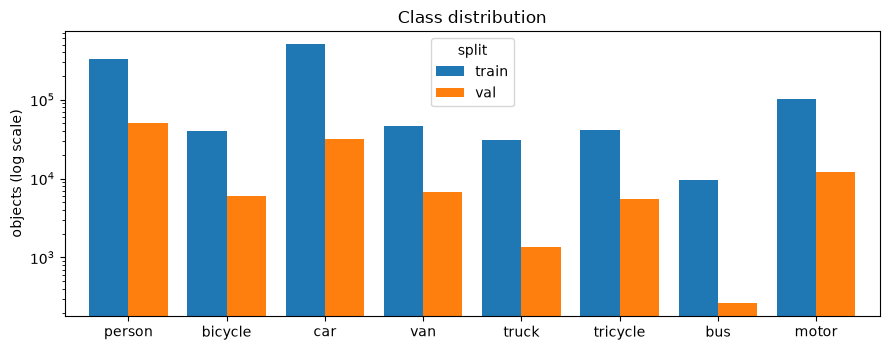

In [6]:
display(hd.class_distribution(objs))
hd.plot_class_distribution(objs);

Classes "person" and "car" are the most dominate in both train and validation data. Howewer, in train data there are slightly more observaltions of class car compared to person, while in validation data the distribution is opposite.

### 1.2 Object sizes and shapes

size_bin,tiny (<16),small (16-32),medium (32-96),large (>=96),median sqrt(area) px,median aspect h/w
class_name,,,,,,
person,3.8,33.8,61.7,0.7,36.700001,2.00
bicycle,2.9,18.8,75.6,2.8,43.900002,1.08
car,0.7,15.2,64.9,19.2,57.599998,0.79
van,0.2,19.2,63.8,16.7,51.299999,0.88
truck,0.0,9.1,57.5,33.4,73.900002,0.93
tricycle,0.6,20.1,65.3,14.0,54.500000,0.95
bus,0.0,4.0,39.4,56.6,111.699997,0.96
motor,4.1,27.3,66.9,1.7,39.799999,1.24


{'scaled sqrt(area) quantiles': {'q5': np.float64(14.1),
  'q25': np.float64(22.7),
  'q50': np.float64(31.8),
  'q75': np.float64(45.9),
  'q95': np.float64(86.1),
  'q99': np.float64(133.7)},
 'aspect h/w quantiles': {'q10': np.float64(0.48),
  'q50': np.float64(1.07),
  'q90': np.float64(2.28)},
 'share below 32 px after resize %': 50.4}

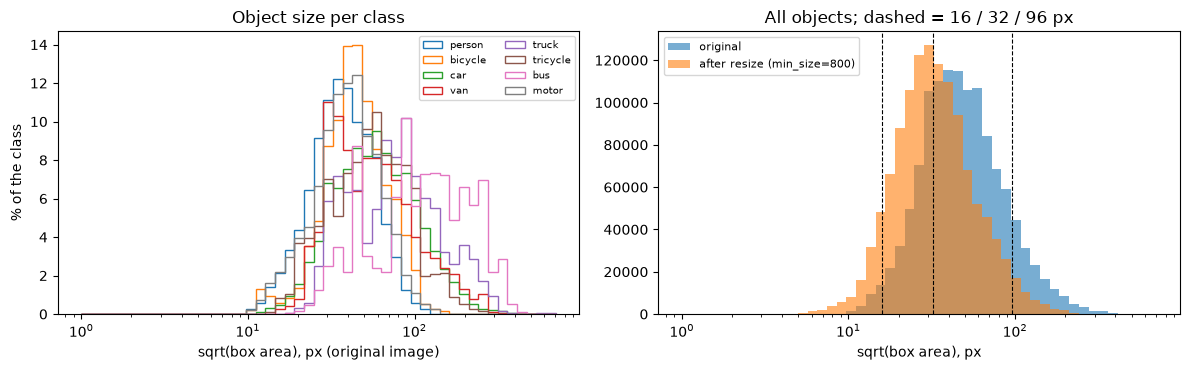

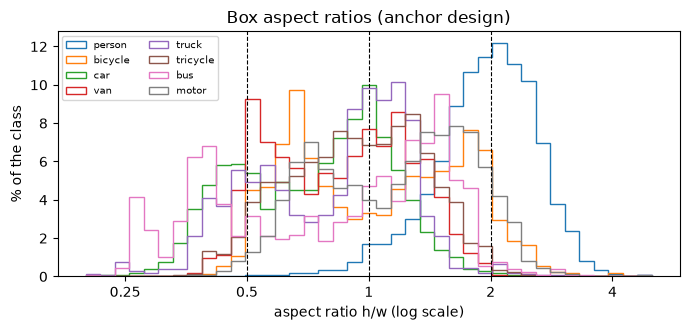

In [7]:
display(hd.size_table(objs))
hd.plot_size_distribution(objs, min_size=800, max_size=1333);
hd.plot_aspect_ratios(objs);
hd.suggest_anchor_stats(objs, min_size=800, max_size=1333)

Before resizing mean object size in pixels was **58.3** and after resizing the mean shrank to **31.8**

The share of tiny object (<16px) remains almost the same - ~5%.

Most of object's aspect ratio lies between 0.5 and 2 and have small left and right tails.
- Class *person* is mostly distributed at aspect ratio >2, which is normal as people normaly don't look like a square.
- Class *bus* is mostly distributed at aspect ration <0.25
- Classes *van* and *bicycke* have spickes at ~0.55 and ~0.7

The default anchor ratios (0.5, 1, 2) cover most objects well and only a few very tall people or very wide buses fall outside the range. Which is why we tune anchor sizes rather than shapes.

### 1.3 Scene density and variation across sequences

,split,frames,resolution,obj/frame mean,obj/frame max,frames with ignore %,median sqrt(area),tiny %,main class,main class %
clip,,,,,,,,,,
uav0000138_00000_v,train,213,2688x1512,143.0,156,100.0,45.400002,0.0,car,41.3
uav0000126_00001_v,train,412,2688x1512,132.2,166,100.0,48.400002,2.6,car,79.2
uav0000124_00944_v,train,398,2688x1512,124.6,134,100.0,46.299999,8.1,car,67.3
uav0000072_04488_v,train,85,1904x1071,110.4,124,0.0,45.799999,0.0,person,87.5
uav0000150_02310_v,train,348,2688x1512,108.9,174,75.0,60.000000,0.0,motor,34.6
...,...,...,...,...,...,...,...,...,...,...
uav0000117_02622_v,val,349,2720x1530,49.5,93,100.0,65.099998,1.4,person,56.0
uav0000182_00000_v,val,363,1344x756,48.7,87,95.0,32.400002,0.5,motor,33.3
uav0000339_00001_v,val,275,1904x1071,43.7,52,100.0,48.500000,0.0,person,45.6


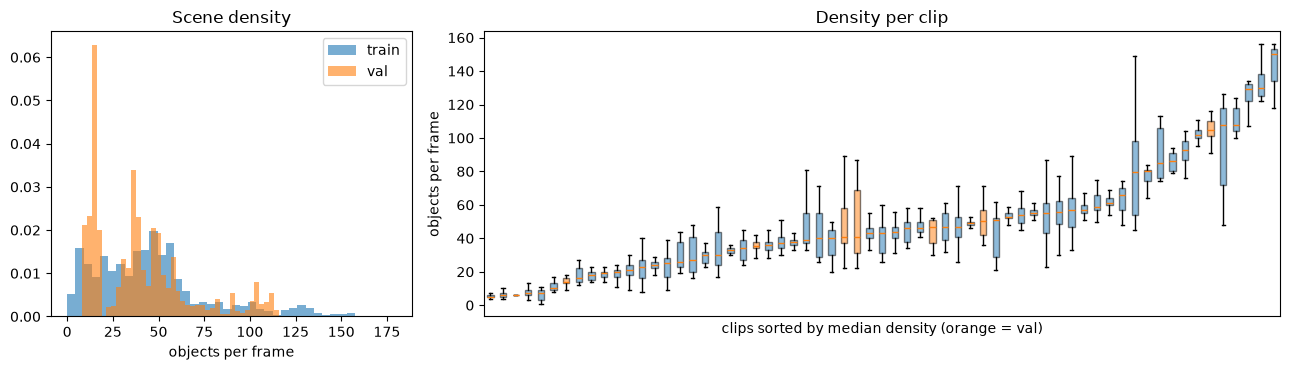

In [8]:
hd.plot_objects_per_frame(all_full);
clip_stats = hd.per_clip_stats(all_full, objs)
display(clip_stats)

**First table:**

In train data scene density is mostly distributed at range from 0 to 60 objects per frame with a tail up to 175 objects.

Validation data is more spiked and less dense. Most of data is at ~15 objects per frame and 30-60 objects per frame.

**Second table:**

Each box is a clip. Density is usually stable but some clips have very high min or max, which creates such long "whiskers".
Similarly to first table, validation clips are spreaded across table. The data includes both low, medium and high density clips.

Scene density ranges from almost empty frames to about 160 objects per frame. The density usually changes more between clips rather than inside on clip, which is why the data both train and validation data are splitted by clip in order to avoid leakage.

### 1.4 Ignored regions

In [9]:
display(pd.DataFrame({"train": hd.ignore_stats(train_full), "val": hd.ignore_stats(val_full)}))

,train,val
frames with ignored regions %,74.70,50.40
regions per frame (when present),3.50,2.80
mean image area covered % (approx.),2.41,1.62
GT boxes >50% inside ignore,11787.00,1199.00
GT boxes total,1105516.00,114132.00


### 1.5 Temporal redundancy (for the frame subsampling step)

In [10]:
redundancy = hd.temporal_redundancy(train_full, lags=(1, 2, 5, 10, 20, 40), n_clips=10, seed=SEED)
redundancy

,pixel_diff,box_persist
lag,,
1,8.305,0.955
2,10.712,0.798
5,16.456,0.394
10,20.241,0.214
20,23.316,0.107
40,25.748,0.098


`pixel_diff` — mean absolute grey-level difference between frame *t* and *t+lag*;
`box_persist` — share of objects at *t* that still have a same-class box with IoU > 0.5 at *t+lag*.

The best choice for train step is **lag 10**.
- lag 1-5 is too small as box persistance remains too high.
- lag 20+ adds too little information and removes too much training data.

So **lag 10** becomes a "golden mean" for `TRAIN_STEP`, as it has good box persistance and doesn't ignore too much data.

## 2. Preprocessing and validation protocol

### 2.1 Annotation conversion check
YOLO `cx cy w h` (normalised) → pixel `x1 y1 x2 y2`. Ground truth in class colours, ignored regions grey/hatched.

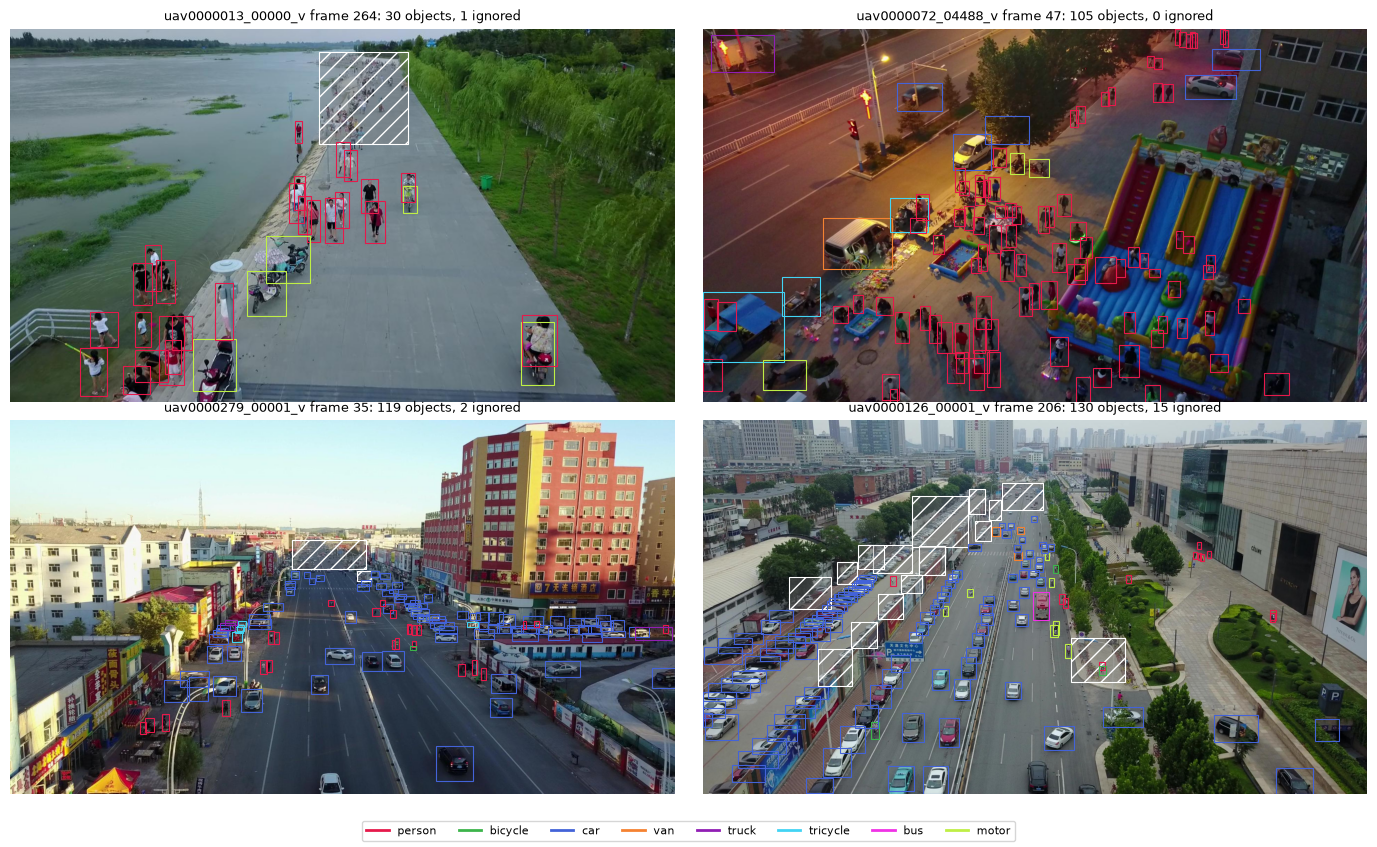

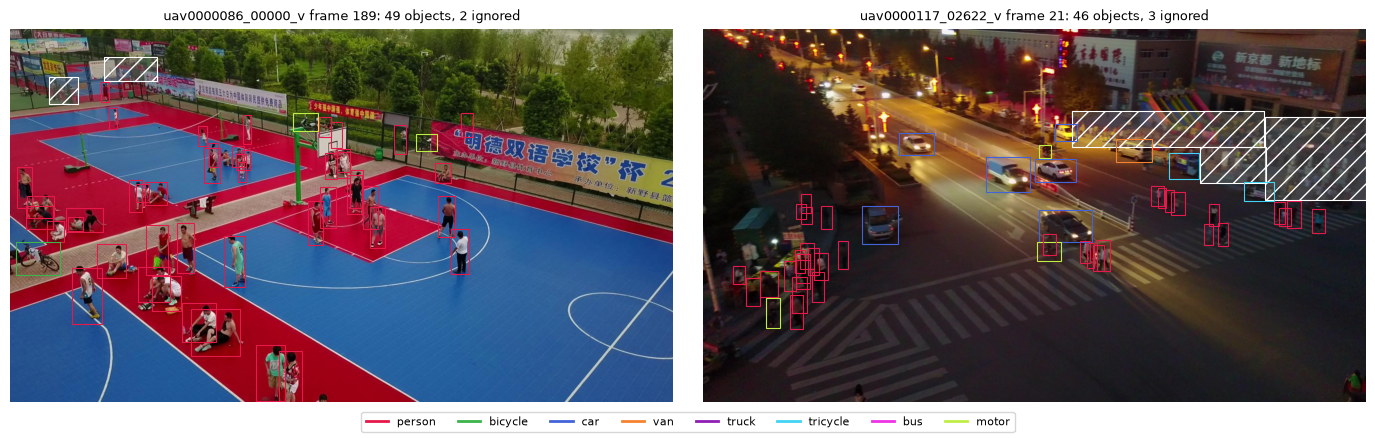

In [11]:
hd.show_gt_samples(train_full, n=4, seed=SEED);
hd.show_gt_samples(val_full, n=2, seed=SEED);

In [12]:
# compare the converted YOLO boxes with annotations_coco.json on random frames
coco_check = hd.crosscheck_with_coco(train_full, DATA_ROOT / "train" / "annotations_coco.json", n_frames=200, seed=SEED)
coco_check.describe().loc[["mean", "min", "max"]]

,yolo_boxes,coco_boxes,yolo_ignore,coco_crowd,mean_best_iou
mean,46.56,46.56,2.82,22.56,0.999959
min,3.00,3.00,0.00,0.00,0.999916
max,152.00,152.00,19.00,152.00,0.999984


In [13]:
# occlusion / truncation from the COCO file, used later in the failure analysis
try:
    val_full = hd.attach_coco_attributes(val_full, DATA_ROOT / "val" / "annotations_coco.json")
    print("val boxes matched to COCO attributes:", sum(int((o >= 0).sum()) for o in val_full["occlusion"]),
          "of", int(val_full["n_obj"].sum()))
except Exception as e:
    print("COCO attributes not attached:", repr(e))

val boxes matched to COCO attributes: 114132 of 114132


**Ignored regions and non-target classes.** VisDrone "ignored regions" and "others" are given only as
ignored regions (no class). During training they are painted with the mean colour and GT boxes lying
more than 50 % inside them are dropped, so the model is neither rewarded nor punished there. During
evaluation, detections lying more than 50 % inside an ignored region are removed before scoring (unless
they match an annotated box), which reproduces "detections there are not penalised".

### 2.2 Split and frame subsampling
The organisers' `val/` clips are a sequence-level hold-out (checked below). All model comparisons use the
same training frames, the same validation frames, the same metric code and the same seed.

In [14]:
print("clips in both train and val:", hd.check_clip_overlap(train_full, val_full) or "none")
train_df = hd.subsample_frames(train_full, TRAIN_STEP)
val_df = hd.subsample_frames(val_full, VAL_STEP)
print(f"train: {len(train_full)} -> {len(train_df)} frames | val: {len(val_full)} -> {len(val_df)} frames")
display(hd.class_distribution(hd.boxes_table(pd.concat([train_df, val_df], ignore_index=True))))

clips in both train and val: none
train: 24201 -> 2446 frames | val: 2846 -> 571 frames


split,train,val,train %,val %
class_name,,,,
person,33493,10089,29.83,44.05
bicycle,4109,1213,3.66,5.30
car,51186,6393,45.59,27.91
van,4762,1371,4.24,5.99
truck,3097,271,2.76,1.18
tricycle,4197,1099,3.74,4.80
bus,983,53,0.88,0.23
motor,10437,2417,9.30,10.55


In [15]:
# optional: clip-level folds (GroupKFold) for later cross-validation of the final pipeline
folds = hd.make_clip_folds(train_full, n_splits=5, seed=SEED)
folds.groupby("fold").agg(clips=("clip", "nunique"), frames=("clip", "size"), objects=("n_obj", "sum"))

,clips,frames,objects
fold,,,
0,10,4830,160543
1,11,4844,170557
2,12,4876,288431
3,11,4787,259822
4,12,4864,226163


### 2.3 Resizing, normalisation, augmentation
* **Resize** (inside every model, same rule): shorter side → 800 px, longer side ≤ 1333 px, aspect ratio kept.
* **Normalisation**: torchvision models use ImageNet mean/std internally; RT-DETR uses 0–1 inputs (as its
  image processor does).
* **Augmentation** (training only): horizontal flip p = 0.5. Colour jitter is available but off in the protocol.
* Reproducibility: fixed seed, seeded DataLoader generator, the same subsampled frames for all models.

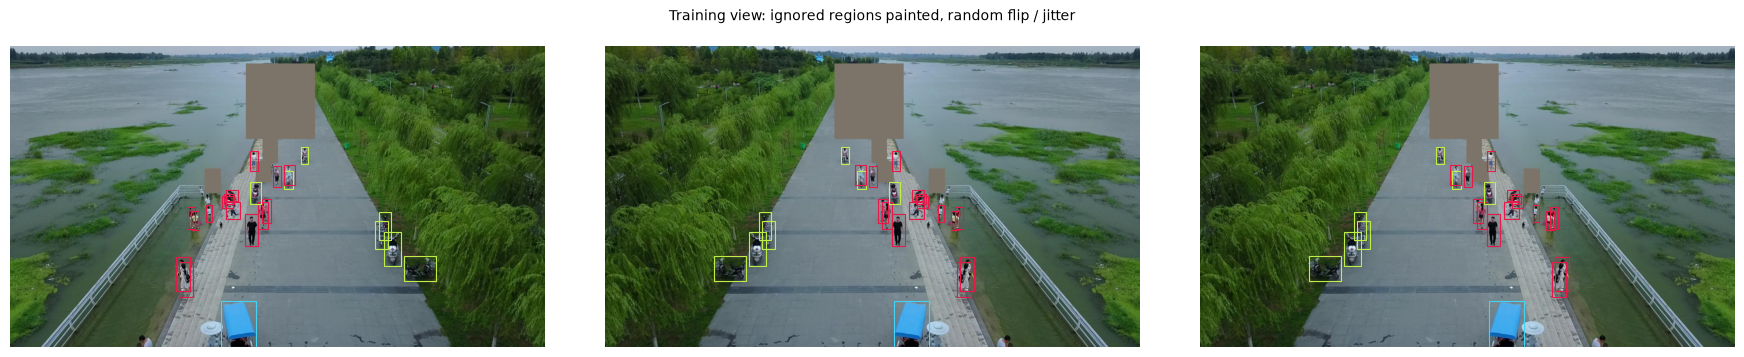

In [16]:
aug_ds = hd.DroneDetDataset(train_df, train=True, mask_ignore=True, hflip_p=0.5)
example = int(np.argmax(train_df["n_ignore"].to_numpy() > 0))  # a frame with ignored regions
hd.show_augmented(aug_ds, example, n=3, seed=SEED);

In [17]:
# shared protocol: every experiment = these settings + the changes listed in its section
PROTOCOL = dict(epochs=EPOCHS, train_step=TRAIN_STEP, val_step=VAL_STEP, max_minutes=MAX_MINUTES, seed=SEED,
                batch_size=BATCH_SIZE, grad_accum=GRAD_ACCUM, eval_batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)
BASE = {arch: hd.make_config(arch, **PROTOCOL) for arch in hd.ARCH_DEFAULTS}
pd.Series({k: v for k, v in BASE["faster_rcnn"].items() if k in hd.COMMON_CFG}, dtype=object).to_frame("value")

,value
pretrained,True
seed,42
min_size,800
max_size,1333
train_step,10
val_step,5
mask_ignore,True
drop_ioa,0.5
hflip_p,0.5
color_jitter,0.0


In [18]:
def experiments(arch, **variants):
    # {run name: config}; each variant = BASE[arch] + its changes
    return {name: hd.make_config(arch, **PROTOCOL, **changes) for name, changes in variants.items()}


def run_or_load(exps, train=True):
    # train (or continue / load if finished) every experiment; returns {name: result}
    out = {}
    for name, cfg in exps.items():
        if train and TRAIN:
            out[name] = hd.run_experiment(name, cfg, train_df, val_df, RESULTS_DIR, EXTRA_RESULTS_DIRS, DEVICE)
        else:
            found = next((Path(d) / name for d in [RESULTS_DIR, *EXTRA_RESULTS_DIRS]
                          if (Path(d) / name / "metrics.json").exists()), None)
            if found is not None:
                out[name] = hd.load_run(found)
            else:
                print(f"[{name}] not trained yet")
    return out


def run_dir(name):
    for d in [RESULTS_DIR, *EXTRA_RESULTS_DIRS]:
        if (Path(d) / name / "metrics.json").exists():
            return Path(d) / name
    raise FileNotFoundError(name)


def best_of(results):
    return max(results.values(), key=lambda r: r["mAP"]) if results else None


def changes_table(exps):
    diffs = {n: {k: str(v) for k, v in hd.config_diff(c, BASE[c["arch"]]).items()} for n, c in exps.items()}
    return pd.DataFrame(diffs).T.fillna("")

## 3. Two-stage anchor-based: Faster R-CNN

`fasterrcnn_resnet50_fpn_v2` (torchvision), COCO-pretrained, new classifier for 8 classes.
Experiments are cumulative (each one keeps the previous change):

1. `frcnn_base` — default settings.
2. `frcnn_props` — more RPN proposals (dense scenes with 100+ objects; default keeps 1000 at test time).
3. `frcnn_props_giou` — + GIoU box regression loss in the second stage instead of smooth-L1.

In [19]:
PROPS = dict(rpn_pre_nms_top_n_train=3000, rpn_post_nms_top_n_train=3000,
             rpn_pre_nms_top_n_test=3000, rpn_post_nms_top_n_test=2000)
FRCNN_EXPS = experiments(
    "faster_rcnn",
    frcnn_base={},
    frcnn_props=PROPS,
    frcnn_props_giou={**PROPS, "box_loss": "giou"},
    # frcnn_props_roi={**PROPS, "box_batch_size_per_image": 1024, "box_positive_fraction": 0.5},  # optional
)
changes_table(FRCNN_EXPS)

,rpn_pre_nms_top_n_train,rpn_pre_nms_top_n_test,rpn_post_nms_top_n_train,rpn_post_nms_top_n_test,box_loss
frcnn_base,,,,,
frcnn_props,3000,3000,3000,2000,
frcnn_props_giou,3000,3000,3000,2000,giou


In [20]:
frcnn_res = run_or_load(FRCNN_EXPS, train=RUN["faster_rcnn"])
hd.results_table(list(frcnn_res.values())) if frcnn_res else None

,arch,mAP,AP50,AP75,AP_tiny,AP_small,AP_medium,AP_large,AR,ms_per_img,fps,params_M,train_minutes,best_epoch
run,,,,,,,,,,,,,,
frcnn_base,faster_rcnn,0.2455,0.4776,0.2229,0.0027,0.1047,0.2214,0.4513,0.3503,76.3,13.10,43.29,67.9,6
frcnn_props,faster_rcnn,0.2417,0.4937,0.2067,0.0167,0.1367,0.2246,0.4219,0.3904,100.3,9.97,43.29,71.3,3
frcnn_props_giou,faster_rcnn,0.2498,0.4939,0.2218,0.0053,0.1206,0.2342,0.4348,0.3989,100.1,9.99,43.29,71.4,4


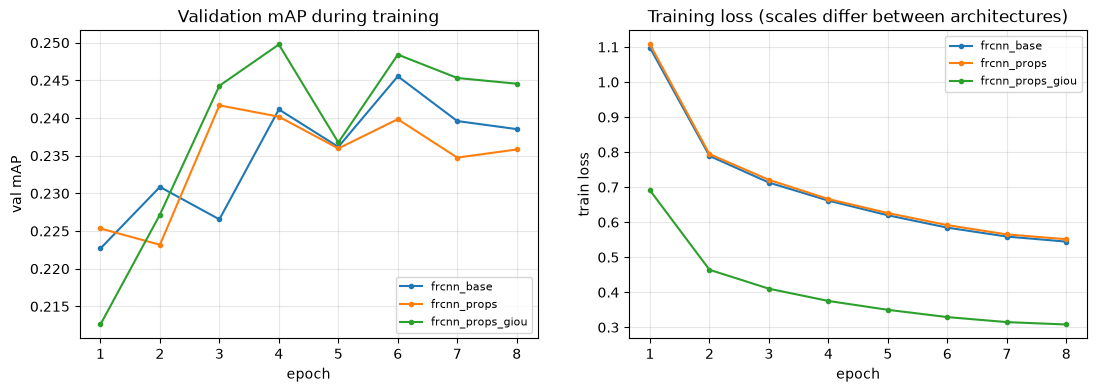

,frcnn_base,frcnn_props,frcnn_props_giou
person,0.2853,0.2744,0.3045
bicycle,0.2383,0.2538,0.2465
car,0.3961,0.3929,0.3992
van,0.2694,0.2808,0.2514
truck,0.3620,0.3183,0.3405
tricycle,0.2690,0.2553,0.2830
bus,0.0116,0.0150,0.0327
motor,0.1327,0.1430,0.1403


In [21]:
if frcnn_res:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    hd.plot_histories({n: r.get("history") for n, r in frcnn_res.items()}, ax=axes[0])
    hd.plot_train_losses({n: r.get("history") for n, r in frcnn_res.items()}, ax=axes[1])
    plt.show()
    display(hd.per_class_table(list(frcnn_res.values())))

### 3.1 What the two stages contribute
For each GT box: is it covered (IoU ≥ 0.5) by the top-N RPN proposals, and by the final detections?
`best_iou_*` shows how much the second stage refines localisation.

In [22]:
FRCNN_BEST = best_of(frcnn_res)["name"] if frcnn_res else None
if FRCNN_BEST and MODEL_ANALYSIS:
    frcnn_model = hd.load_model_from_run(run_dir(FRCNN_BEST), DEVICE)
    display(hd.rpn_proposal_recall(frcnn_model, val_df, DEVICE, n_images=100, top_ns=(100, 300, 1000, 2000)))
    del frcnn_model
    torch.cuda.empty_cache()

,objects,proposals@100,proposals@300,proposals@1000,proposals@2000,best_iou_proposal,final (any class),final (correct class),best_iou_final
size_bin,,,,,,,,,
tiny (<16),9,0.000,0.111,0.333,0.333,0.311,0.222,0.222,0.253
small (16-32),683,0.556,0.685,0.763,0.767,0.627,0.668,0.624,0.535
medium (32-96),2817,0.643,0.771,0.861,0.878,0.700,0.793,0.754,0.631
large (>=96),506,0.925,0.970,0.986,0.988,0.844,0.970,0.955,0.821
all,4015,0.663,0.780,0.859,0.871,0.705,0.793,0.756,0.638


The **RPN** sets the upper bound: only boxes covered by a proposal can be detected. Proposal recall grows from 66% (top-100) to 87% (top-2000). 

The gain is largest for small objects (56% → 77%), which explains why more proposals improved AP_small. 

The second stage classifies and filters proposals: recall drops to 79% for any class and 76% for the correct class, so about 8% of objects are lost to the score threshold and NMS and about 4% to a wrong class. 

Losses are small for large objects (99% → 97%) and largest for small ones (77% → 62%). The tiny bin has only 9 objects, so it is not reliable.

### 3.2 Failure cases
Error types at score ≥ 0.3: missed objects, background false positives, wrong class, poor localisation, duplicates.
Green = correct, red = false positive, yellow dashed = missed, grey = ignored region.

In [23]:
def failure_report(name, score_thr=0.3):
    preds = hd.load_val_preds(run_dir(name))
    gt_tab, pr_tab, conf = hd.analyze_failures(val_df, preds, score_thr=score_thr)
    for title, tab in hd.failure_summary(gt_tab, pr_tab).items():
        print("--", title)
        display(tab)
    print("-- class confusions (rows = GT, columns = prediction)")
    display(conf)
    return preds, gt_tab, pr_tab


if FRCNN_BEST:
    frcnn_preds, frcnn_gt_tab, frcnn_pr_tab = failure_report(FRCNN_BEST)

-- recall by size


,size,mean
size_bin,,
tiny (<16),77,0.130
small (16-32),4318,0.515
medium (32-96),15916,0.675
large (>=96),2595,0.902


-- recall by class


,size,mean
class_name,,
bicycle,1213,0.564
bus,53,0.000
car,6393,0.689
motor,2417,0.540
person,10089,0.744
tricycle,1099,0.588
truck,271,0.683
van,1371,0.430


-- recall by density


,size,mean
density,,
"[0.0, 50.0)",10902,0.587
"[50.0, 100.0)",7744,0.706
"[100.0, 200.0)",4260,0.811


... (2 outputs left out)

-- recall by occlusion


,size,mean
occlusion,,
0,9372,0.809
1,12014,0.616
2,1520,0.222


-- class confusions (rows = GT, columns = prediction)


,pred person,pred bicycle,pred car,pred van,pred truck,pred tricycle,pred bus,pred motor
GT person,0,39,0,0,0,7,0,118
GT bicycle,90,0,0,0,0,21,0,383
GT car,1,0,0,153,67,34,1,0
GT van,0,0,715,0,49,17,22,0
GT truck,0,0,2,8,0,26,1,0
GT tricycle,16,7,56,18,98,0,0,54
GT bus,0,0,33,32,20,0,0,0
GT motor,610,167,1,0,0,100,0,0


c:\Users\admin\Desktop\hw\pavlunyshyn_hw2_AI\hw2_detection.py:1942: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  fig.tight_layout()


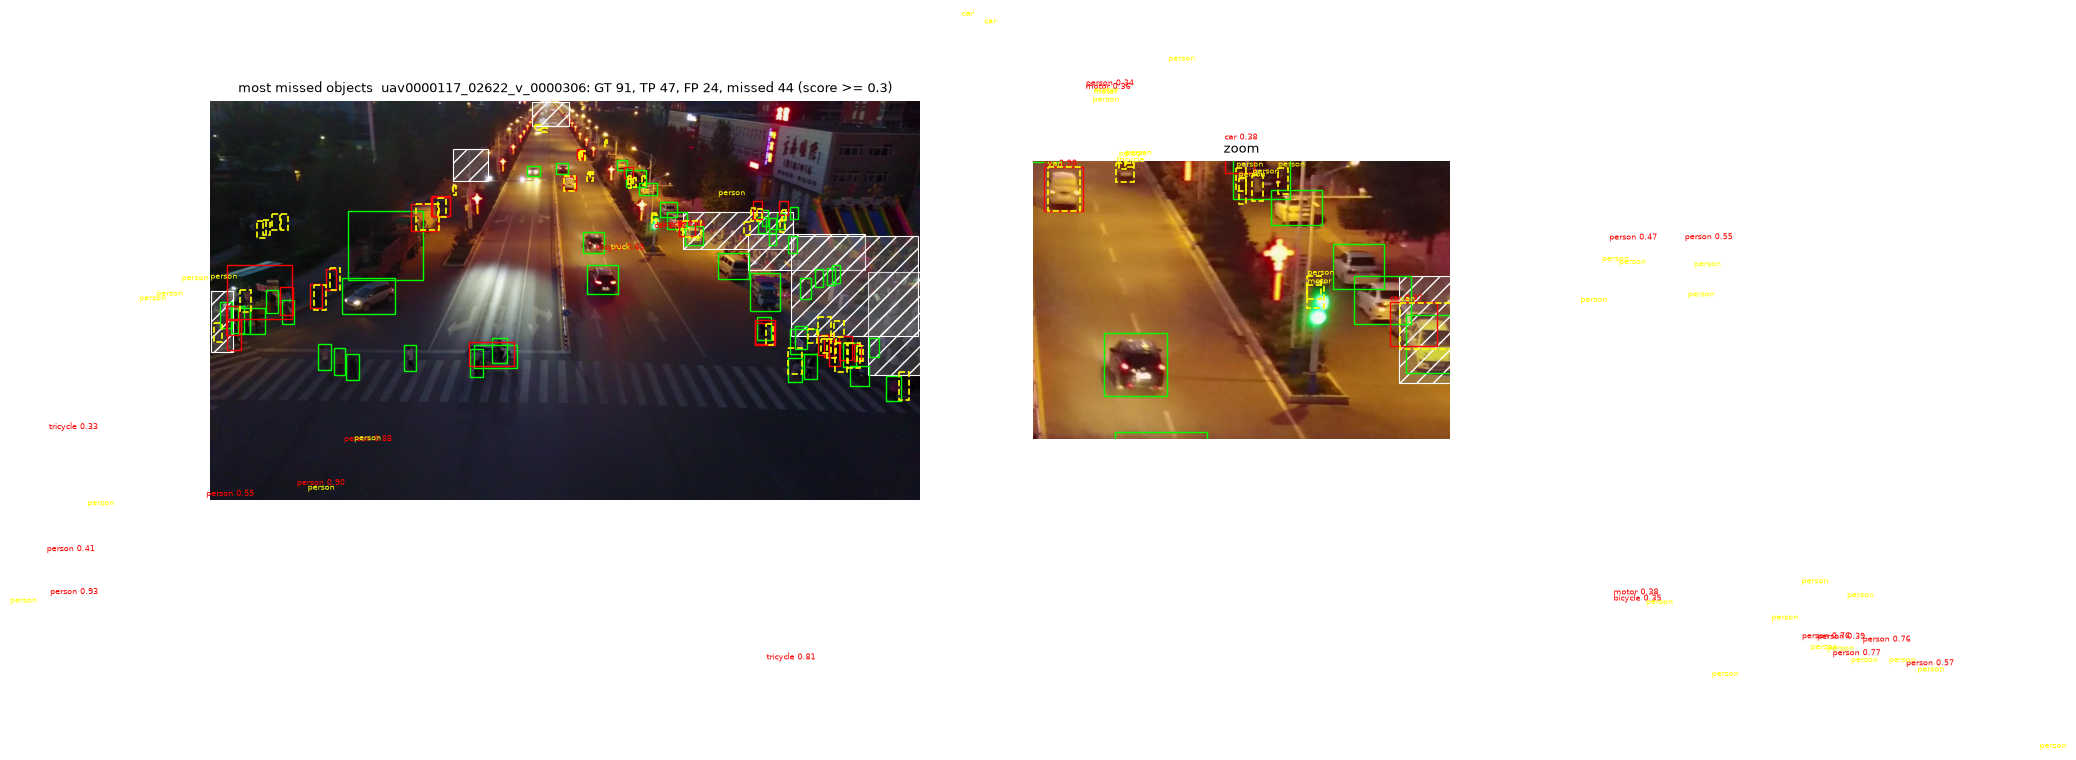

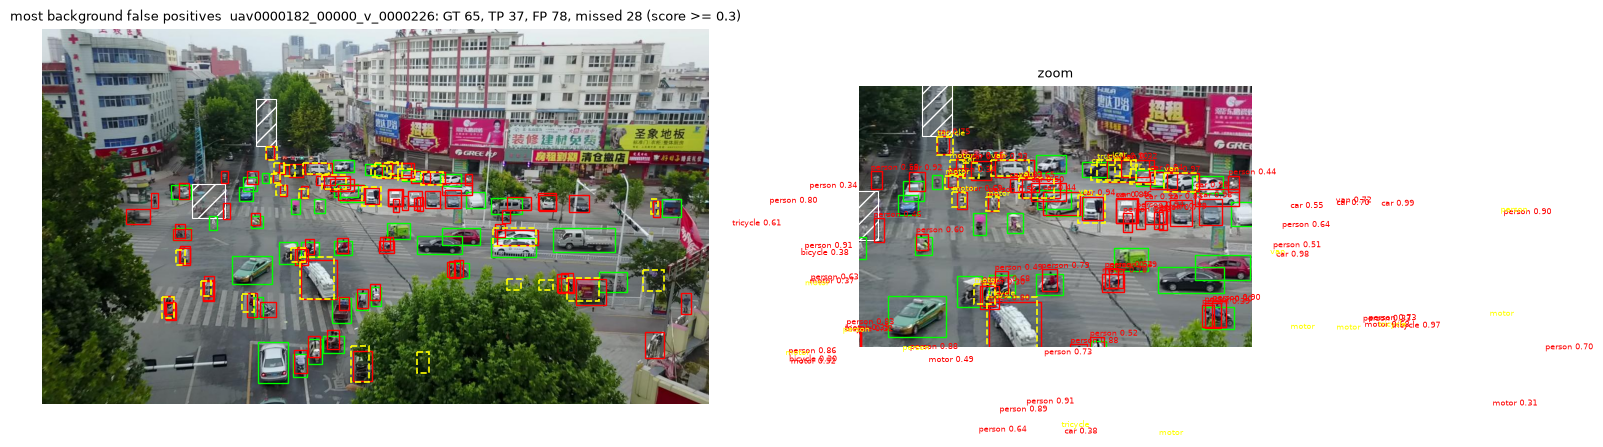

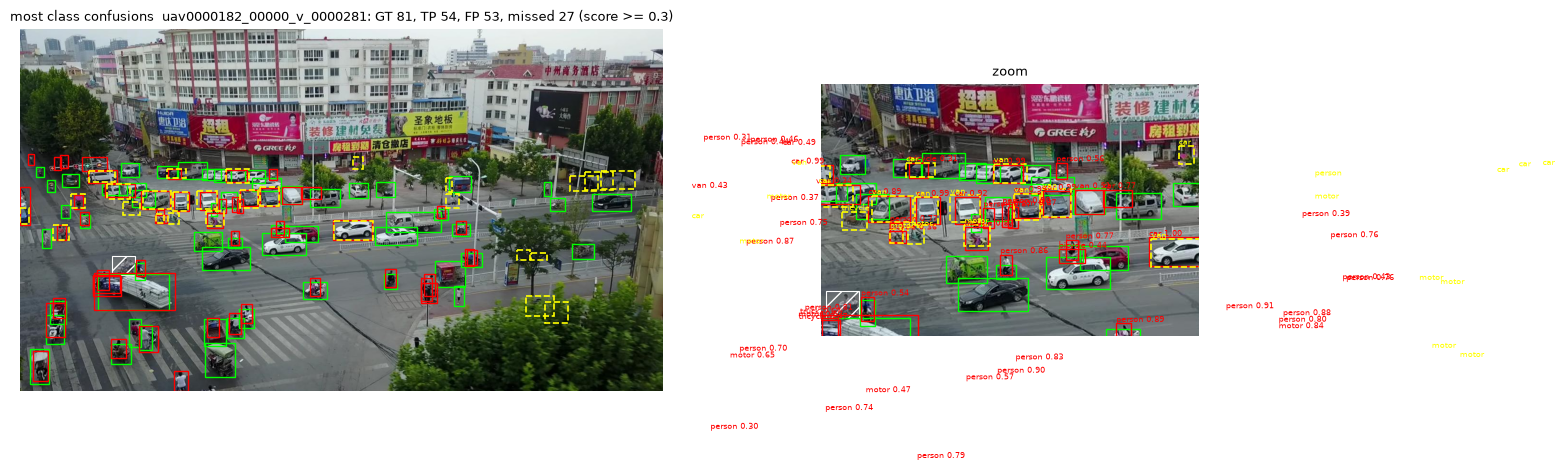

In [24]:
if FRCNN_BEST:
    for title, rows in hd.pick_failure_frames(frcnn_gt_tab, frcnn_pr_tab, n_each=1).items():
        for row in rows:
            hd.plot_failure_frame(val_df, frcnn_preds, row, score_thr=0.3, title=title)
            plt.show()

**Case 1** — missed small and occluded objects (frame with most missed objects). Recall falls from 0.90 for large objects to 0.52 for small and 0.13 for tiny ones, and from 0.81 for non-occluded to 0.22 for heavily occluded objects. After resizing these objects cover only a few cells of the stride-4/8 feature maps, and occlusion hides most of the visible pixels, so the **RPN** gives them weak proposals.

**Case 2** — background false positives (22% of all predictions). The model fires on object-like background: road marks, roof details, shadows, parked-car-like shapes. Without temporal context single frames are ambiguous from high altitude.

**Case 3** — confusion of similar classes. The largest errors are motor → person (610), van → car (715) and bicycle → motor (383). A rider and a motorbike share almost the same box, and from above a van looks like a large car. Buses have recall 0: only 53 val instances, so the rare class is absorbed by car/van/truck.

**Recall** grows with density (0.59 → 0.81): dense clips are mostly roads and parking lots with medium-size cars, while sparse clips are often filmed from higher altitude with smaller objects.

## 4. One-stage anchor-based: RetinaNet

`retinanet_resnet50_fpn_v2` (torchvision), COCO-pretrained, same protocol.
First check how well anchor sets match the object sizes from section 1 (after resize).

In [25]:
DEFAULT_ANCHORS = hd.retinanet_anchor_sizes((32, 64, 128, 256, 512))
SMALL_ANCHORS = hd.retinanet_anchor_sizes((16, 32, 64, 128, 256))   # chosen from section 1.2
RATIOS = (0.5, 1.0, 2.0)
flat = lambda sizes: [s for level in sizes for s in level]
print("default:", DEFAULT_ANCHORS)
print("small  :", SMALL_ANCHORS)
pd.concat({"default anchors": hd.anchor_coverage(objs, flat(DEFAULT_ANCHORS), RATIOS),
           "small anchors": hd.anchor_coverage(objs, flat(SMALL_ANCHORS), RATIOS)}, axis=1)

default: ((32, 40, 50), (64, 80, 101), (128, 161, 203), (256, 322, 406), (512, 645, 812))
small  : ((16, 20, 25), (32, 40, 50), (64, 80, 101), (128, 161, 203), (256, 322, 406))


default anchors                           small anchors                          
                       objects mean_best_iou covered_pct       objects mean_best_iou covered_pct
size_bin                                                                                        
large (>=96)            140980         0.829        99.8        140980         0.829        99.8
medium (32-96)          781382         0.744        90.4        781382         0.826        99.9
small (16-32)           272954         0.407        24.8        272954         0.790        95.4
tiny (<16)               24332         0.138         0.0         24332         0.536        55.2
all                    1219648         0.667        75.0       1219648         0.812        98.0

`covered_pct` = share of GT boxes whose best anchor shape reaches IoU ≥ 0.5 (the positive threshold),
centres aligned — an upper bound for the real assignment.

In [26]:
RETINA_EXPS = experiments(
    "retinanet",
    retina_base={},
    retina_anchors={"anchor_base_sizes": (16, 32, 64, 128, 256)},
    retina_anchors_focal={"anchor_base_sizes": (16, 32, 64, 128, 256), "focal_gamma": 1.5},
)
changes_table(RETINA_EXPS)

,anchor_base_sizes,focal_gamma
retina_base,,
retina_anchors,"(16, 32, 64, 128, 256)",
retina_anchors_focal,"(16, 32, 64, 128, 256)",1.5


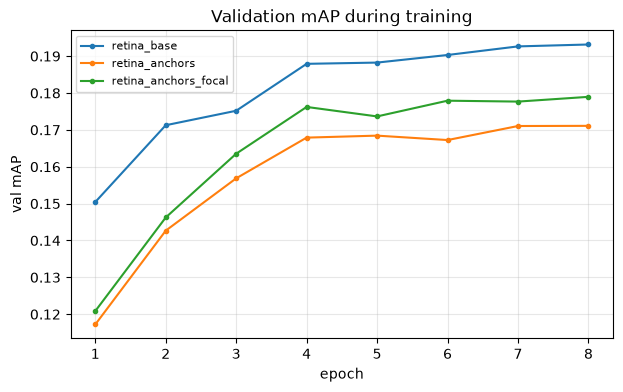

,arch,mAP,AP50,AP75,AP_tiny,AP_small,AP_medium,AP_large,AR,ms_per_img,fps,params_M,train_minutes,best_epoch
run,,,,,,,,,,,,,,
retina_base,retinanet,0.1932,0.3690,0.1798,0.0015,0.0776,0.1923,0.3549,0.3569,54.5,18.34,36.48,50.3,8
retina_anchors,retinanet,0.1711,0.3669,0.1367,0.0019,0.0695,0.1578,0.3005,0.3831,55.8,17.93,36.48,52.6,8
retina_anchors_focal,retinanet,0.1790,0.3812,0.1407,0.0036,0.0693,0.1620,0.3236,0.3788,56.0,17.85,36.48,52.9,8
frcnn_props_giou,faster_rcnn,0.2498,0.4939,0.2218,0.0053,0.1206,0.2342,0.4348,0.3989,100.1,9.99,43.29,71.4,4


In [27]:
retina_res = run_or_load(RETINA_EXPS, train=RUN["retinanet"])
if retina_res:
    hd.plot_histories({n: r.get("history") for n, r in retina_res.items()})
    plt.show()
compare = list(retina_res.values()) + ([frcnn_res[FRCNN_BEST]] if FRCNN_BEST else [])
hd.results_table(compare) if compare else None

**RetinaNet** classifies ~100k anchors directly, and almost all of them are background. This imbalance is handled by **focal loss**, which down-weights easy negatives. There is also no second refinement step (RoI pooling + box head), so localisation is coarser: AP75 is 0.180 vs 0.222 for **Faster R-CNN**. Anchor coverage suggested smaller anchors: with 32-px base anchors only 25% of small and 0% of tiny objects can reach IoU ≥ 0.5, with 16-px anchors 95% and 55%. 

In training smaller anchors lowered *mAP* (0.193 → 0.171) and *AP_large* (0.355 → 0.300) while *AR* rose (0.357 → 0.383): more objects were found, but with worse precision and localisation, and large objects lost their biggest anchors (812 → 406 px). 

Focal gamma 1.5 recovered part of the drop (0.179). The best **RetinaNet** stays well below the **tuned two-stage model** (0.193 vs 0.250, AP_small 0.078 vs 0.121), but it is **~1.8× faster**.

## 5. One-stage anchor-free: FCOS

`FCOS ResNet-50-FPN` (torchvision), COCO-pretrained. Every feature-map point is a candidate; it is positive
for a box if it lies inside the box, near its centre (`center_sampling_radius × stride`) and the box size fits
the FPN level. The simulation below counts positive locations per GT box for different settings.

In [28]:
assign = {}
for label, strides, radius in [("P3-P7, r=1.5 (default)", hd.fcos_strides(False), 1.5),
                               ("P3-P7, r=2.5", hd.fcos_strides(False), 2.5),
                               ("P2-P7, r=1.5", hd.fcos_strides(True), 1.5)]:
    tab, summary = hd.fcos_assignment_stats(train_df, strides=strides, center_radius=radius, n_images=300, seed=SEED)
    assign[label] = tab
    print(label, summary)
pd.concat(assign, axis=1)

P3-P7, r=1.5 (default) {'strides': [8, 16, 32, 64, 128], 'center_radius': 1.5, 'GT without any positive location %': 1.62, 'ambiguous locations (claimed by >1 box) %': 6.71}
P3-P7, r=2.5 {'strides': [8, 16, 32, 64, 128], 'center_radius': 2.5, 'GT without any positive location %': 1.35, 'ambiguous locations (claimed by >1 box) %': 8.6}
P2-P7, r=1.5 {'strides': [4, 8, 16, 32, 64, 128], 'center_radius': 1.5, 'GT without any positive location %': 0.3, 'ambiguous locations (claimed by >1 box) %': 2.99}


P3-P7, r=1.5 (default)                                                          P3-P7, r=2.5                                                          P2-P7, r=1.5                     \
                              objects mean_pos_locations no_positive_pct lost_to_other_box_pct      objects mean_pos_locations no_positive_pct lost_to_other_box_pct      objects mean_pos_locations   
size_bin                                                                                                                                                                                               
tiny (<16)                        398               1.84           18.59                  5.28          398               1.84           18.59                  5.28          398               5.64   
small (16-32)                    3336               4.75            2.52                 14.27         3336               5.61            2.49                 15.14         3336               8.20   
medium (32-96)                   9435               7.64            0.89                 21.80         9435              14.58            0.48                 31.97         9435               9.65   
large (>=96)                     1745              10.15            0.00                  5.39         1745              27.02            0.00                 16.68         1745              10.46   

                                                      
               no_positive_pct lost_to_other_box_pct  
size_bin                                              
tiny (<16)                1.51                  8.54  
small (16-32)             0.33                  9.95  
medium (32-96)            0.29                 10.55  
large (>=96)              0.00                  4.47

In [29]:
FCOS_EXPS = experiments(
    "fcos",
    fcos_base={},
    fcos_p2={"p2_level": True},                       # extra high-resolution level (stride 4)
    fcos_p2_ciou={"p2_level": True, "box_loss": "ciou"},
)
changes_table(FCOS_EXPS)

,p2_level,box_loss
fcos_base,,
fcos_p2,True,
fcos_p2_ciou,True,ciou


In [30]:
# fcos_p2_ciou did not finish (compute limit): evaluate its best checkpoint after 4/8 epochs, no more training
import pickle
name = "fcos_p2_ciou"
rd = RESULTS_DIR / name
if not IN_COLAB and not (rd / "metrics.json").exists():
    with open(rd / "config.json") as f:
        cfg = json.load(f)
    with open(rd / "history.json") as f:
        hist = json.load(f)
    model = hd.load_model_from_run(rd, DEVICE)
    preds = hd.predict_df(model, val_df, cfg, DEVICE)
    res = {"name": name, "arch": cfg["arch"], **hd.evaluate_coco(val_df, preds), **hd.count_params(model),
           "ms_per_img": None, "fps": None,  # measured on a different GPU, not comparable
           "train_minutes": hist["minutes"][-1], "best_epoch": hist["best_epoch"],
            "epochs_done": len(hist["epoch"]), "note": f"stopped after {len(hist['epoch'])}/8 epochs (compute limit)"}
    with open(rd / "val_preds.pkl", "wb") as f:
        pickle.dump(preds, f)
    with open(rd / "metrics.json", "w") as f:
        json.dump(res, f, indent=1)
    del model
    torch.cuda.empty_cache()
    print(name, "evaluated: mAP", round(res["mAP"], 4))

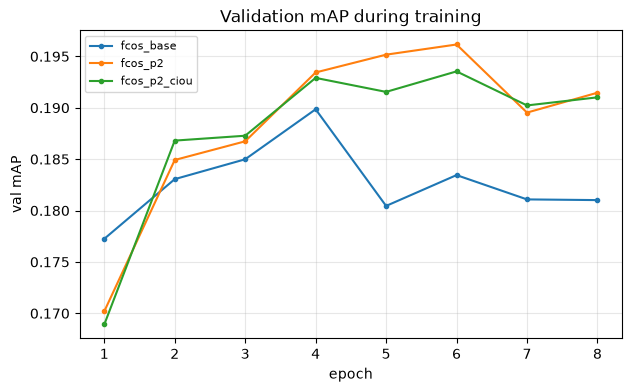

,arch,mAP,AP50,AP_tiny,AP_small,AP_medium,AP_large,AR,fps
run,,,,,,,,,
fcos_base,fcos,0.1898,0.3751,0.0106,0.0938,0.1736,0.3441,0.4061,12.71
fcos_p2,fcos,0.1962,0.3902,0.0040,0.0885,0.1667,0.3652,0.4278,7.05
fcos_p2_ciou,fcos,0.1935,0.3881,0.0030,0.0941,0.1664,0.3609,0.4327,6.70
frcnn_props_giou,faster_rcnn,0.2498,0.4939,0.0053,0.1206,0.2342,0.4348,0.3989,9.99
retina_base,retinanet,0.1932,0.3690,0.0015,0.0776,0.1923,0.3549,0.3569,18.34


In [31]:
fcos_res = run_or_load(FCOS_EXPS, train=RUN["fcos"])
if fcos_res:
    hd.plot_histories({n: r.get("history") for n, r in fcos_res.items()})
    plt.show()
compare = list(fcos_res.values()) + [r for r in (best_of(frcnn_res), best_of(retina_res)) if r]
hd.results_table(compare, cols=["mAP", "AP50", "AP_tiny", "AP_small", "AP_medium", "AP_large", "AR", "fps"]) if compare else None

In **FCOS** every feature-map location is a candidate. Each candidate becomes **positive** for a box if it lies inside the **radius ×** from the box centre, and the box size fits the scale range of that FPN level; if several boxes claim a location, the smallest box wins. 

For small and dense objects this is a problem: with the default P3–P7 and radius 1.5, 18.6% of tiny objects get no positive location at all, and 6.7% of locations are claimed by more than one box. A larger radius (2.5) does not help tiny objects and increases ambiguity (8.6%), while an extra P2 level (stride 4) reduces tiny objects without positives to 1.5% and ambiguity to 3%.

Search range: P2 level {off, on}, box loss {GIoU, CIoU}; the radius was only studied in simulation. In training, P2 gave +0.006 mAP (within noise), and *AP_small* did not improve (0.094 → 0.089); only *AP_large* grew (0.344 → 0.365). CIoU gave no further gain (0.194). The new P2 layers start from random weights and shallow features, which 8 epochs did not seem to be enough for. **FCOS** (0.19–0.20) is on par with **RetinaNet** (0.193) and below **Faster R-CNN** (0.250).

## 6. Query-based: RT-DETR

`PekingU/rtdetr_r50vd` (Hugging Face), COCO-pretrained, same resize rule, same epochs. AdamW,
backbone learning rate × 0.1. The number of queries is the maximum number of objects the model can output
per image, so it is compared with the scene density first.

In [32]:
print("objects per frame quantiles (train):")
print(train_full["n_obj"].quantile([0.5, 0.9, 0.99, 1.0]).round(0).to_dict())

objects per frame quantiles (train):
{0.5: 43.0, 0.9: 92.0, 0.99: 142.0, 1.0: 180.0}


In [33]:
RTDETR_EXPS = experiments(
    "rtdetr",
    rtdetr_base={"amp": False},                       # fp32: fp16 gives NaN on GTX 16xx GPUs
    rtdetr_q500={"num_queries": 500, "amp": False},
    # rtdetr_q500_giou={"num_queries": 500, "matcher_giou_cost": 4.0, "weight_loss_giou": 4.0},
)
changes_table(RTDETR_EXPS)

,amp,num_queries
rtdetr_base,False,
rtdetr_q500,False,500


In [34]:
rtdetr_res = run_or_load(RTDETR_EXPS, train=RUN["rtdetr"])
hd.results_table(list(rtdetr_res.values())) if rtdetr_res else None

,arch,mAP,AP50,AP75,AP_tiny,AP_small,AP_medium,AP_large,AR,ms_per_img,fps,params_M,train_minutes,best_epoch
run,,,,,,,,,,,,,,
rtdetr_base,rtdetr,0.2479,0.4894,0.2199,0.0050,0.1282,0.2356,0.4173,0.4892,119.6,8.36,42.74,91.1,5
rtdetr_q500,rtdetr,0.2532,0.5008,0.2213,0.0036,0.1300,0.2402,0.4181,0.4802,122.4,8.17,42.74,90.0,4


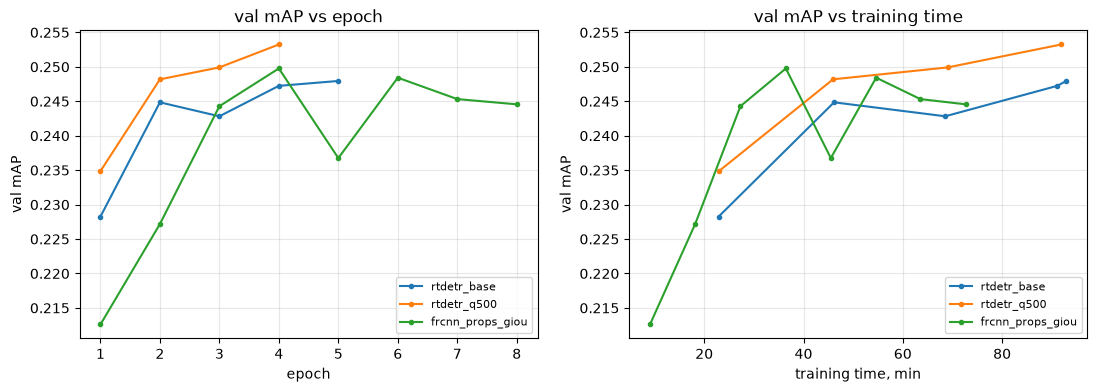

In [35]:
CNN_BEST = best_of({**frcnn_res, **retina_res, **fcos_res})
if rtdetr_res and CNN_BEST:
    curves = {**{n: r.get("history") for n, r in rtdetr_res.items()}, CNN_BEST["name"]: CNN_BEST.get("history")}
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    hd.plot_histories(curves, x="epoch", ax=axes[0], title="val mAP vs epoch")
    hd.plot_histories(curves, x="minutes", ax=axes[1], title="val mAP vs training time")
    plt.show()

In [36]:
# small objects and dense scenes: RT-DETR vs the best CNN on the same frames
if rtdetr_res and CNN_BEST:
    RTDETR_BEST = best_of(rtdetr_res)["name"]
    dens = {}
    for name in (RTDETR_BEST, CNN_BEST["name"]):
        dens[name] = hd.ap_by_density(val_df, hd.load_val_preds(run_dir(name)), bins=(0, 50, 100, 200, np.inf))
    display(pd.concat(dens, axis=1))
    display(hd.results_table([rtdetr_res[RTDETR_BEST], CNN_BEST],
                             cols=["mAP", "AP50", "AP_tiny", "AP_small", "AP_medium", "AP_large", "AR", "fps"]))

rtdetr_q500                                         frcnn_props_giou                                        
                    frames       mAP      AP50  AP_small        AR           frames       mAP      AP50  AP_small        AR
objects/frame                                                                                                              
[0.0, 50.0)            410  0.236493  0.431640  0.111544  0.481866              410  0.231166  0.423979  0.133934  0.384219
[50.0, 100.0)          121  0.279198  0.588731  0.134867  0.443117              121  0.281631  0.591816  0.120732  0.407597
[100.0, 200.0)          40  0.356125  0.701102  0.020202  0.515870               40  0.350459  0.749282  0.016740  0.468147

,arch,mAP,AP50,AP_tiny,AP_small,AP_medium,AP_large,AR,fps
run,,,,,,,,,
rtdetr_q500,rtdetr,0.2532,0.5008,0.0036,0.1300,0.2402,0.4181,0.4802,8.17
frcnn_props_giou,faster_rcnn,0.2498,0.4939,0.0053,0.1206,0.2342,0.4348,0.3989,9.99


**Bipartite (Hungarian) matching** assigns each ground-truth object to exactly one query and all other queries to “no object”. The model is trained not to produce duplicates, so no NMS is needed.


In training this gives sparse supervision (one positive per object), which usually makes DETR-style models converge slowly; **RT-DETR** reduces this with denoising queries, and we start from COCO weights. The number of queries was compared with scene density: 99% of frames have ≤ 142 objects (max 180), so 300 queries is only ~2 per object in the densest frames; 500 queries gave a small gain (*mAP* 0.248 → 0.253, AP50 0.489 → 0.501).


Both runs did not converge: the 90-minute budget **stopped them after 4–5 of 8 epochs**, with the loss still falling. They were trained on a slower GPU in fp32 (fp16 gave NaN losses), so they got less compute than the CNNs for the same time. Still, **RT-DETR** matches the best Faster R-CNN (0.253 vs 0.250) and is ahead of it at every epoch. Without NMS it keeps more neighbouring objects: *AR* is 0.48 vs 0.40 at every density level, and *mAP* on the densest frames is slightly higher (0.356 vs 0.350). On small objects it is better on average (*AP_small* 0.130 vs 0.121) but worse in sparse frames (0.112 vs 0.134), and both models almost fail on small objects in the densest frames (*AP_small* ≈ 0.02).

## 7. Comparison of all models

,arch,mAP,AP50,AP75,AP_tiny,AP_small,AP_medium,AP_large,AR,ms_per_img,fps,params_M,train_minutes,best_epoch
run,,,,,,,,,,,,,,
frcnn_base,faster_rcnn,0.2455,0.4776,0.2229,0.0027,0.1047,0.2214,0.4513,0.3503,76.3,13.10,43.29,67.9,6
frcnn_props,faster_rcnn,0.2417,0.4937,0.2067,0.0167,0.1367,0.2246,0.4219,0.3904,100.3,9.97,43.29,71.3,3
frcnn_props_giou,faster_rcnn,0.2498,0.4939,0.2218,0.0053,0.1206,0.2342,0.4348,0.3989,100.1,9.99,43.29,71.4,4
retina_base,retinanet,0.1932,0.3690,0.1798,0.0015,0.0776,0.1923,0.3549,0.3569,54.5,18.34,36.48,50.3,8
retina_anchors,retinanet,0.1711,0.3669,0.1367,0.0019,0.0695,0.1578,0.3005,0.3831,55.8,17.93,36.48,52.6,8
retina_anchors_focal,retinanet,0.1790,0.3812,0.1407,0.0036,0.0693,0.1620,0.3236,0.3788,56.0,17.85,36.48,52.9,8
fcos_base,fcos,0.1898,0.3751,0.1715,0.0106,0.0938,0.1736,0.3441,0.4061,78.7,12.71,32.08,62.0,4
fcos_p2,fcos,0.1962,0.3902,0.1729,0.0040,0.0885,0.1667,0.3652,0.4278,141.9,7.05,32.73,123.3,6
fcos_p2_ciou,fcos,0.1935,0.3881,0.1690,0.0030,0.0941,0.1664,0.3609,0.4327,149.2,6.70,32.73,122.6,6


,frcnn_base,frcnn_props,frcnn_props_giou,retina_base,retina_anchors,retina_anchors_focal,fcos_base,fcos_p2,fcos_p2_ciou,rtdetr_base,rtdetr_q500
person,0.2853,0.2744,0.3045,0.2515,0.2428,0.2431,0.2614,0.2643,0.2676,0.3135,0.3120
bicycle,0.2383,0.2538,0.2465,0.1422,0.1737,0.1816,0.1649,0.1979,0.2001,0.2609,0.2706
car,0.3961,0.3929,0.3992,0.3730,0.3361,0.3385,0.3765,0.3778,0.3748,0.4170,0.4255
van,0.2694,0.2808,0.2514,0.2375,0.2030,0.2202,0.2099,0.2313,0.1993,0.3035,0.2769
truck,0.3620,0.3183,0.3405,0.1982,0.1650,0.1736,0.1823,0.1822,0.1862,0.2550,0.2809
tricycle,0.2690,0.2553,0.2830,0.1925,0.1467,0.1685,0.2033,0.1839,0.1829,0.2567,0.2732
bus,0.0116,0.0150,0.0327,0.0699,0.0107,0.0113,0.0138,0.0196,0.0239,0.0408,0.0542
motor,0.1327,0.1430,0.1403,0.0805,0.0908,0.0948,0.1066,0.1125,0.1135,0.1362,0.1325


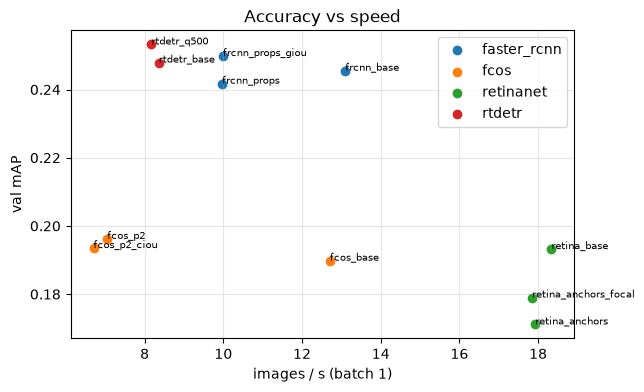

In [37]:
ALL_RES = {**frcnn_res, **retina_res, **fcos_res, **rtdetr_res}
if ALL_RES:
    summary = hd.results_table(list(ALL_RES.values()))
    display(summary)
    display(hd.per_class_table(list(ALL_RES.values())))
    fig, ax = plt.subplots(figsize=(6.5, 4))
    for arch, g in summary.groupby("arch"):
        ax.scatter(g["fps"], g["mAP"], label=arch)
        for name, r in g.iterrows():
            ax.annotate(name, (r["fps"], r["mAP"]), fontsize=7)
    ax.set_xlabel("images / s (batch 1)")
    ax.set_ylabel("val mAP")
    ax.set_title("Accuracy vs speed")
    ax.grid(alpha=0.3)
    ax.legend()
    plt.show()
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    summary.to_csv(RESULTS_DIR / "summary_required_models.csv")

**Two groups appear:** the **two-stage Faster R-CNN** (0.24–0.25 mAP) and the **query-based RT-DETR** (0.25) clearly beat the one-stage CNNs, RetinaNet and FCOS (0.17–0.20). 

The best single model is *rtdetr_q500* **(0.253)**, within noise of *frcnn_props_giou* **(0.250)**. Per class, car and person are detected best, while bus (rare, AP ≤ 0.07) and motor (often confused with person) are the hardest. *AP_tiny* is near zero for all models but is based on only ~77 objects. **RetinaNet is the fastest** (18 img/s) and **FCOS with P2 the slowest** (7 img/s); RT-DETR speed was measured on a different GPU in fp32 and is not directly comparable.

## 8. Baseline submission
Predictions of the best required model (by validation mAP) on the test set — a valid submission to check the
format and beat the baseline early. It is not the final pipeline.

In [38]:
if MAKE_SUBMISSION and ALL_RES:
    best = best_of(ALL_RES)
    print("model:", best["name"], "| val mAP", round(best["mAP"], 4))
    model = hd.load_model_from_run(run_dir(best["name"]), DEVICE)
    with open(run_dir(best["name"]) / "config.json") as f:
        best_cfg = json.load(f)
    test_preds = hd.predict_df(model, test_df, best_cfg, DEVICE)
    sub_path = WORK_DIR / f"submission_{best['name']}.csv"
    hd.make_submission(test_df, test_preds, sub_path, max_det=500)
    reference = next(DATA_ROOT.glob("sample_submission*.csv"), DATA_ROOT / "test_images.csv")
    print(hd.validate_submission(sub_path, reference))
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

## 9. Your pipeline

Built on the best required model (`frcnn_props_giou`, section 7). Every step is measured on the same
validation frames, so the effect of each change is visible:

* **Part A — data / inference strategy** (same weights, no retraining): A1 lower score threshold (more
  low-confidence candidates, up to 500 per image), A2 NMS threshold for dense scenes, A3 horizontal-flip
  test-time augmentation, A5 ensemble with another detector (checked on saved predictions).
* **Part B — model**: B1 = the same Faster R-CNN with smaller RPN anchors (16–256 px instead of 32–512 px),
  motivated by section 1.2 (half of the objects are smaller than 32 px after resizing). Same protocol as
  `frcnn_props_giou`, so "0 vs B1" isolates the model change.

Predictions of every step are cached in `pipeline/`, so nothing is computed twice.

In [39]:
# ---- pipeline settings ----
PIPE_BASE = "frcnn_props_giou"         # best required model by validation mAP (section 7)
B1_NAME = "frcnn_anchors16"            # part B: the same model with smaller RPN anchors
PIPE_DIR = WORK_DIR / "pipeline"       # cached predictions of every step (val and test)
PIPELINE_A = HAS_GPU and not IN_COLAB  # part A (inference experiments) runs on the local GPU
PIPELINE_B_TRAIN = False                # part B model is trained locally (overnight)
FINAL_TEST = False                      # predict the test set with the final pipeline (80-160 min locally)
LOW_SCORE, LOOSE_NMS, MAX_DET = 0.001, 0.7, 500
PIPE_DIR.mkdir(parents=True, exist_ok=True)


def eval_row(step, change, preds):
    # one line of the pipeline table: validation metrics of a set of predictions
    m = hd.evaluate_coco(val_df, preds, per_class=False)
    return {"step": step, "change": change,
            **{k: round(m[k], 4) for k in ("mAP", "AP50", "AP_small", "AP_tiny", "AR")},
            "dets/img": round(float(np.mean([len(p["boxes"]) for p in preds])), 1)}


def pipeline_preds(name, df, split, flip):
    # cached predictions of model `name` on `split` ("val"/"test"): plain pass and (optionally) flipped pass.
    # Low score threshold and loose NMS here; the final NMS is applied afterwards on the CPU.
    with open(run_dir(name) / "config.json") as f:
        cfg = json.load(f)
    cfg.update(eval_batch_size=1, num_workers=0)  # one image at a time: fits a 6 GB GPU
    model = None

    def get_model():
        nonlocal model
        if model is None:
            model = hd.load_model_from_run(run_dir(name), DEVICE)
            hd.set_inference_params(model, score_thresh=LOW_SCORE, nms_thresh=LOOSE_NMS, max_det=2 * MAX_DET)
        return model

    plain = hd.cached(PIPE_DIR / f"{split}_{name}_low.pkl", lambda: hd.predict_df(get_model(), df, cfg, DEVICE))
    flipped = None
    if flip:
        flipped = hd.cached(PIPE_DIR / f"{split}_{name}_low_flip.pkl",
                            lambda: hd.predict_flip(get_model(), df, DEVICE, amp=cfg["amp"]))
    if model is not None:
        del model
        torch.cuda.empty_cache()
    return plain, flipped


pipe_rows, candidates = [], {}   # candidates: (model, flip TTA, NMS) -> validation mAP

### 9.1 Part A — inference strategy (same weights)

In [40]:
if PIPELINE_A:
    p0 = hd.load_val_preds(run_dir(PIPE_BASE))
    pipe_rows.append(eval_row("0", f"{PIPE_BASE} as trained (score >= 0.05, NMS 0.5)", p0))

    # A1 + A2: one pass with score >= 0.001 and loose NMS 0.7, then NMS 0.5 / 0.6 / 0.7 on the CPU
    p_low, p_flip = pipeline_preds(PIPE_BASE, val_df, "val", flip=True)
    for thr in (0.5, 0.6, 0.7):
        row = eval_row(f"A1+A2 (NMS {thr})", f"score >= {LOW_SCORE}, up to {MAX_DET} dets, NMS {thr}",
                       hd.nms_preds(p_low, thr, MAX_DET))
        pipe_rows.append(row)
        candidates[(PIPE_BASE, False, thr)] = row["mAP"]
    BEST_NMS = max((0.5, 0.6, 0.7), key=lambda t: candidates[(PIPE_BASE, False, t)])

    # A3: + horizontal-flip test-time augmentation (flipped boxes mapped back, merged with NMS)
    row = eval_row("A3", f"+ flip TTA (NMS {BEST_NMS})", hd.merge_preds([p_low, p_flip], BEST_NMS, MAX_DET))
    pipe_rows.append(row)
    candidates[(PIPE_BASE, True, BEST_NMS)] = row["mAP"]
    display(pd.DataFrame(pipe_rows).set_index("step"))

,change,mAP,AP50,AP_small,AP_tiny,AR,dets/img
step,,,,,,,
0,"frcnn_props_giou as trained (score >= 0.05, NM...",0.2498,0.4939,0.1206,0.0053,0.3989,117.7
A1+A2 (NMS 0.5),"score >= 0.001, up to 500 dets, NMS 0.5",0.2562,0.5104,0.1252,0.0058,0.4572,414.0
A1+A2 (NMS 0.6),"score >= 0.001, up to 500 dets, NMS 0.6",0.2558,0.5054,0.1257,0.0056,0.4648,496.2
A1+A2 (NMS 0.7),"score >= 0.001, up to 500 dets, NMS 0.7",0.2489,0.4769,0.1236,0.0052,0.4691,500.0
A3,+ flip TTA (NMS 0.5),0.2549,0.5178,0.1215,0.0050,0.4663,493.6


In [41]:
# A5: ensemble of the base model with the best RetinaNet / FCOS (saved validation predictions, CPU only)
ens_rows = []
others = [r for r in (best_of(retina_res), best_of(fcos_res)) if r]
if others and (run_dir(PIPE_BASE) / "val_preds.pkl").exists():
    p0 = hd.load_val_preds(run_dir(PIPE_BASE))
    ens_rows.append(eval_row("0", f"{PIPE_BASE} alone (as trained)", p0))
    for r in others:
        merged = hd.merge_preds([p0, hd.load_val_preds(run_dir(r["name"]))], 0.5, MAX_DET)
        ens_rows.append(eval_row("A5", f"{PIPE_BASE} + {r['name']} (NMS 0.5)", merged))
pd.DataFrame(ens_rows).set_index("step") if ens_rows else None

,change,mAP,AP50,AP_small,AP_tiny,AR,dets/img
step,,,,,,,
0,frcnn_props_giou alone (as trained),0.2498,0.4939,0.1206,0.0053,0.3989,117.7
A5,frcnn_props_giou + retina_base (NMS 0.5),0.2548,0.4996,0.1236,0.0055,0.4437,232.6
A5,frcnn_props_giou + fcos_p2 (NMS 0.5),0.2482,0.4896,0.1270,0.0055,0.4539,364.3


### 9.2 Part B — model change: smaller RPN anchors

In [42]:
with open(run_dir(PIPE_BASE) / "config.json") as f:
    base_saved = json.load(f)
b1_cfg = hd.make_config("faster_rcnn", **{**PROTOCOL, **PROPS, "box_loss": "giou",
                                          "rpn_anchor_sizes": (16, 32, 64, 128, 256), "max_minutes": None})
print("differences from", PIPE_BASE, ":", hd.config_diff(json.loads(json.dumps(b1_cfg)), base_saved))
pipe_b = run_or_load({B1_NAME: b1_cfg}, train=PIPELINE_B_TRAIN)

differences from frcnn_props_giou : {'batch_size': 2, 'grad_accum': 2, 'eval_batch_size': 2, 'num_workers': 0, 'rpn_anchor_sizes': [16, 32, 64, 128, 256]}


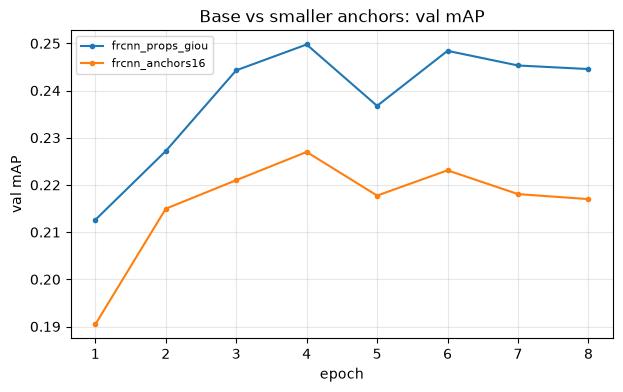

In [43]:
if pipe_b:
    p_b1 = hd.load_val_preds(run_dir(B1_NAME))
    if not pipe_rows:
        pipe_rows.append(eval_row("0", f"{PIPE_BASE} as trained (score >= 0.05, NMS 0.5)",
                                  hd.load_val_preds(run_dir(PIPE_BASE))))
    pipe_rows.append(eval_row("B1", f"{B1_NAME} as trained (RPN anchors 16-256 px)", p_b1))
    if PIPELINE_A:
        b_low, b_flip = pipeline_preds(B1_NAME, val_df, "val", flip=True)
        row = eval_row("B1+A2", f"{B1_NAME}, score >= {LOW_SCORE}, NMS {BEST_NMS}", hd.nms_preds(b_low, BEST_NMS, MAX_DET))
        pipe_rows.append(row)
        candidates[(B1_NAME, False, BEST_NMS)] = row["mAP"]
        row = eval_row("B1+A3", f"{B1_NAME} + flip TTA (NMS {BEST_NMS})", hd.merge_preds([b_low, b_flip], BEST_NMS, MAX_DET))
        pipe_rows.append(row)
        candidates[(B1_NAME, True, BEST_NMS)] = row["mAP"]
    hd.plot_histories({PIPE_BASE: hd.load_run(run_dir(PIPE_BASE)).get("history"),
                       B1_NAME: pipe_b[B1_NAME].get("history")}, title="Base vs smaller anchors: val mAP")
    plt.show()

### 9.3 Pipeline summary and final submission

In [44]:
if pipe_rows:
    pipe_table = pd.DataFrame(pipe_rows).set_index("step")
    display(pipe_table)
    pipe_table.to_csv(PIPE_DIR / "pipeline_table.csv")
if candidates:
    FINAL = max(candidates, key=candidates.get)
    print("final pipeline: model = %s, flip TTA = %s, NMS = %.1f, val mAP = %.4f" % (*FINAL, candidates[FINAL]))

,change,mAP,AP50,AP_small,AP_tiny,AR,dets/img
step,,,,,,,
0,"frcnn_props_giou as trained (score >= 0.05, NM...",0.2498,0.4939,0.1206,0.0053,0.3989,117.7
A1+A2 (NMS 0.5),"score >= 0.001, up to 500 dets, NMS 0.5",0.2562,0.5104,0.1252,0.0058,0.4572,414.0
A1+A2 (NMS 0.6),"score >= 0.001, up to 500 dets, NMS 0.6",0.2558,0.5054,0.1257,0.0056,0.4648,496.2
A1+A2 (NMS 0.7),"score >= 0.001, up to 500 dets, NMS 0.7",0.2489,0.4769,0.1236,0.0052,0.4691,500.0
A3,+ flip TTA (NMS 0.5),0.2549,0.5178,0.1215,0.0050,0.4663,493.6
B1,frcnn_anchors16 as trained (RPN anchors 16-256...,0.2270,0.4610,0.1201,0.0061,0.3427,112.1
B1+A2,"frcnn_anchors16, score >= 0.001, NMS 0.5",0.2322,0.4755,0.1232,0.0065,0.3783,381.2
B1+A3,frcnn_anchors16 + flip TTA (NMS 0.5),0.2300,0.4778,0.1249,0.0060,0.3923,492.5


final pipeline: model = frcnn_props_giou, flip TTA = False, NMS = 0.5, val mAP = 0.2562


In [45]:
if FINAL_TEST and candidates:
    name, flip, nms = FINAL
    t_low, t_flip = pipeline_preds(name, test_df, "test", flip=flip)
    final_test = hd.merge_preds([t_low, t_flip], nms, MAX_DET) if flip else hd.nms_preds(t_low, nms, MAX_DET)
    sub_path = WORK_DIR / f"submission_pipeline_{name}{'_flip' if flip else ''}_nms{nms}.csv"
    hd.make_submission(test_df, final_test, sub_path, max_det=MAX_DET)
    sub = pd.read_csv(sub_path, keep_default_na=False)  # Kaggle rejects empty strings
    sub.loc[sub["PredictionString"].astype(str).str.strip() == "", "PredictionString"] = "0 0.0001 0.0 0.0 1.0 1.0"
    sub.to_csv(sub_path, index=False)
    reference = next(DATA_ROOT.glob("sample_submission*.csv"), DATA_ROOT / "test_images.csv")
    print(sub_path)
    print(hd.validate_submission(sub_path, reference))

### 9.4 Part B (revised) — ensemble of a two-stage CNN and a query-based detector
B1 (smaller RPN anchors) was stopped: on our local GPU it reached val mAP 0.000 after 2 epochs at 2-3 hours
per epoch (most likely fp16 problems on a GTX 16xx GPU). Instead, part B combines the two strongest
detectors of different families: Faster R-CNN (`frcnn_props_giou` with A1) and RT-DETR (`rtdetr_q500`).

In [46]:
ENS_MODEL = "rtdetr_q500"
fr_val, _ = pipeline_preds(PIPE_BASE, val_df, "val", flip=False)   # cached Faster R-CNN predictions (score >= 0.001)
fr_val = hd.nms_preds(fr_val, 0.5, MAX_DET)                        # A1 setting chosen in part A
rt_val = hd.load_val_preds(run_dir(ENS_MODEL))                      # RT-DETR (no NMS, top-500 per image)

ens_rows = [eval_row("A1", f"{PIPE_BASE}, score >= {LOW_SCORE}, NMS 0.5", fr_val),
            eval_row("RT", f"{ENS_MODEL} alone", rt_val)]
ens_scores = {}
for w_rt in (1.0, 0.7):
    for thr in (0.5, 0.6):
        merged = hd.merge_preds([fr_val, rt_val], thr, MAX_DET, weights=[1.0, w_rt])
        row = eval_row(f"B2 (w={w_rt}, NMS {thr})", f"{PIPE_BASE} + {ENS_MODEL}, RT-DETR score x{w_rt}, NMS {thr}", merged)
        ens_rows.append(row)
        ens_scores[(w_rt, thr)] = row["mAP"]
ens_table = pd.DataFrame(ens_rows).set_index("step")
ens_table.to_csv(PIPE_DIR / "ensemble_table.csv")
BEST_ENS = max(ens_scores, key=ens_scores.get)
print("best ensemble: RT-DETR weight = %.1f, NMS = %.1f, val mAP = %.4f" % (*BEST_ENS, ens_scores[BEST_ENS]))
ens_table

best ensemble: RT-DETR weight = 1.0, NMS = 0.6, val mAP = 0.2663


,change,mAP,AP50,AP_small,AP_tiny,AR,dets/img
step,,,,,,,
A1,"frcnn_props_giou, score >= 0.001, NMS 0.5",0.2562,0.5104,0.1252,0.0058,0.4572,414.0
RT,rtdetr_q500 alone,0.2532,0.5008,0.1300,0.0036,0.4802,500.0
"B2 (w=1.0, NMS 0.5)","frcnn_props_giou + rtdetr_q500, RT-DETR score ...",0.2655,0.5282,0.1414,0.0069,0.4943,499.0
"B2 (w=1.0, NMS 0.6)","frcnn_props_giou + rtdetr_q500, RT-DETR score ...",0.2663,0.5289,0.1427,0.0067,0.4966,500.0
"B2 (w=0.7, NMS 0.5)","frcnn_props_giou + rtdetr_q500, RT-DETR score ...",0.2642,0.5248,0.1381,0.0068,0.4948,499.1
"B2 (w=0.7, NMS 0.6)","frcnn_props_giou + rtdetr_q500, RT-DETR score ...",0.2650,0.5256,0.1393,0.0066,0.4968,500.0


**Part A (inference, same weights)**. Lowering the score threshold to 0.001 and keeping up to 500 detections (A1) gave +0.006 mAP and +0.058 AR at no training cost, because mAP rewards extra low-confidence true positives. NMS 0.6 was equal to 0.5, while 0.7 hurt (more duplicates). Horizontal-flip TTA did not help (0.2549): merging the two passes with NMS keeps one of two slightly shifted boxes instead of averaging them, so AP50 rose a little but stricter IoU thresholds fell; box fusion (WBF) could be tried instead. Ensembling with RetinaNet gave a small gain, with FCOS none.

**Part B (model)**. B1, smaller RPN anchors (16–256 px), made results worse (0.227 vs 0.250) and did not improve AP_small: small objects already received proposals through low-quality matches, while large objects lost the 512-px anchors. On our local GTX 16xx GPU the same run reached mAP 0.000 (fp16 problems), so it was retrained on a T4. B2, an ensemble of Faster R-CNN (with A1) and RT-DETR q500, was the best: 0.2663 mAP (+0.010 over A1), with higher AP_small (0.143) and AR (0.497). The two detector families make different errors, so their union helps. Final submission: B2 with NMS 0.6 and up to 300 detections per image (the 500-detection file failed on Kaggle with an internal scoring error); public score 0.282 vs baseline 0.222.

In [47]:
SUB_MAX_DET = 300   # lighter file than 500: faster upload and scoring on Kaggle
w_rt, thr = BEST_ENS
with open(run_dir(ENS_MODEL) / "config.json") as f:
    rt_cfg = json.load(f)
rt_cfg.update(eval_batch_size=1, num_workers=0)

fr_test, _ = pipeline_preds(PIPE_BASE, test_df, "test", flip=False)   # cached since yesterday
rt_test = hd.cached(PIPE_DIR / f"test_{ENS_MODEL}.pkl",
                    lambda: hd.predict_df(hd.load_model_from_run(run_dir(ENS_MODEL), DEVICE), test_df, rt_cfg, DEVICE))
ens_test = hd.merge_preds([hd.nms_preds(fr_test, 0.5, MAX_DET), rt_test], thr, SUB_MAX_DET, weights=[1.0, w_rt])

sub_path = WORK_DIR / f"submission_ensemble_frcnn_rtdetr_w{w_rt}_nms{thr}_top{SUB_MAX_DET}.csv"
hd.make_submission(test_df, ens_test, sub_path, max_det=SUB_MAX_DET)
sub = pd.read_csv(sub_path, keep_default_na=False)
sub.loc[sub["PredictionString"].astype(str).str.strip() == "", "PredictionString"] = "0 0.0001 0.0 0.0 1.0 1.0"
sub.to_csv(sub_path, index=False)
print(sub_path, round(sub_path.stat().st_size / 1e6, 1), "MB")
print(hd.validate_submission(sub_path, DATA_ROOT / "test_images.csv"))

C:\AI_DATA\hw2_runs\submission_ensemble_frcnn_rtdetr_w1.0_nms0.6_top300.csv 35.6 MB
{'ok': True, 'problems': [], 'rows': 3811, 'mean detections/image': 299.9, 'max detections/image': 300}


In [ ]:
# # ---- figures for the report (saved to images/ in the repository) ----
# IMG_DIR = module_dir / "images"
# IMG_DIR.mkdir(exist_ok=True)

# def save(fig, name):
#     fig.savefig(IMG_DIR / name, dpi=110, bbox_inches="tight")
#     plt.close(fig)

# save(hd.plot_class_distribution(objs), "class_distribution.png")
# save(hd.plot_size_distribution(objs), "object_sizes.png")
# save(hd.plot_objects_per_frame(all_full), "density_per_clip.png")

# fig, axes = plt.subplots(1, 2, figsize=(13, 4))
# hd.plot_histories(curves, x="epoch", ax=axes[0], title="val mAP vs epoch")
# hd.plot_histories(curves, x="minutes", ax=axes[1], title="val mAP vs training time")
# save(fig, "rtdetr_vs_cnn.png")

# for title, rows in hd.pick_failure_frames(frcnn_gt_tab, frcnn_pr_tab, n_each=1).items():
#     save(hd.plot_failure_frame(val_df, frcnn_preds, rows[0], score_thr=0.3, title=title),
#          f"failure_{title.split()[1]}.png")
# print(sorted(p.name for p in IMG_DIR.glob("*.png")))

c:\Users\admin\Desktop\hw\pavlunyshyn_hw2_AI\hw2_detection.py:1942: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  fig.tight_layout()


['class_distribution.png', 'density_per_clip.png', 'failure_background.png', 'failure_class.png', 'failure_missed.png', 'object_sizes.png', 'rtdetr_vs_cnn.png']
